# d14_two_feedline_resonator — two feedlines, twelve λ/4 resonators, six Xmons (legacy Quantum Metal design 14), on the Quantcore PDK

## 1 · What the chip is

**Source:** the author's legacy design notebook `components/python/14.0 Two_feedline_resonator_chip.ipynb` (Quantum
Metal `DesignPlanar`), Quantcore internal. Spec: `docs/designs/legacy/d14_two_feedline_resonator.md`.

A 10 × 10 mm resonator chip: two straight 20/12 µm feedlines at y = ±1.9 mm, each with six λ/4 CPW resonators (10/6
µm) alternating above and below the line at x = −3.25 … +3.25 mm. Lengths come from the notebook's own 1/f = a·L + b
calibration for 6.50, 6.00, 5.50, 5.00, 5.25, 7.00 GHz (left → right). On the bottom feedline each resonator's open
end is the claw of a `TransmonCross` (Xmon). Eight launchpads, two per edge; only the left ↔ right pairs carry
feedlines. Beside both feedlines the source etches rows of 5 µm flux-trap holes (§8).

| | the rebuild keeps (source-faithful) | the Quantcore PDK changes |
|---|---|---|
| resonators, Xmons | the calibration fit and the resonator plan (`_legacy_b.d14_plan()` prints the legacy §5 table digit for digit); every Metal component with the legacy options through the `metal:` wrapper (`TransmonCross` with the 12.0 claw, `OpenToGround`) at the legacy positions; the 14 route lengths; the 500 µm couplers 36 µm off the feedline (3 µm ground strip) with the shorts at the legacy positions; 70 µm bends | — |
| launchpads | eight `LaunchpadWirebondDriven`s with the legacy options | the rule `pad_edge` = 100 µm (`C.pads_to_edge`): the legacy launchpads already sit exactly 100 µm in, so nothing moves (step 7) |
| junctions | — (the legacy `JJ_grad` cell is external) | the PDK `Quantcore Junction` on each Metal junction line, R_n 45 kΩ |
| cheese | the source's feedline rows of flux holes (5 µm, 25 µm pitch, ≥ 30 µm from any etch: the legacy filter) | the source's holes stay, and the PDK cheese covers the rest of the die (`cheese: "chip"`: 5 µm squares with 20 µm gaps, at least 4 µm from the 3/0 keep-outs, which cover every structure and hole array, so no PDK hole touches one) |
| die, placement | the 10 × 10 mm legacy die, centred | the PDK frame drawn on the 10 mm box; device ID `D14` |

**Simplified or substituted**: KQC `Meander`s on the straight drop at x = xc instead of Metal's
`RouteMeander` (same length, coupler, short and open-end positions; footprints compared below); the flux holes: the
feedline rows only (984 of the legacy 5884 holes; the four rows that follow every meander are left out:
`FluxHoleArray` is rectangular); a 20 µm launchpad lead on the four connected pads (the rest of the legacy 500 µm
lead is the first 480 µm of the feedline route, so resonator 0's coupler runs beside it as in the source).

### Changes after design review (2026-11-03)

- **#12 loaded vs bare readouts — noted** (review note: "yes they were simulated without the claws"). The legacy lengths
  come from a calibration of *bare* λ/4 resonators (no Xmon claw at the open end). The bottom-row resonators end on
  an Xmon claw, which adds ≈ 125 fF to the open end and pulls them below the bare value at the same length; the
  legacy plan gives both rows the same lengths, so the two rows do not sit at the same frequencies. Lengths kept as
  in the source (retuning the bottom row for the claw is a design decision).
- **#10 die:** 10 × 10 mm with the PDK frame drawn on it (confirmed).
- **#1 / #21 junctions — PDK trilayer cell, PDK rule.** The Metal junction footprints (2/0 only) are replaced by the
  PDK `Quantcore Junction` cell (fingers 2/0 + 4/0, spacer 50/0 with the 51–53/0 gradient, CLEARER box) on each
  junction line, sized by the PDK junction rule (Nb, Δ = 1.4 meV, I_c·R_n = πΔ/2e = 2.20 mV, R_n 40–50 kΩ):
  R_n = 45 kΩ → L_J 6.73 nH, C_J 15 fF (`junction_params={"lj_nH": 6.73}`). The earlier assumed L_J = 10 nH /
  C_J = 2 fF are gone.

### PDK conformance pass (notebooks-legacy, 2026-11-18)

- **Pads:** `C.pads_to_edge(d)` (pins the hangers given by `s` first, then `edge="auto"` on all eight launchpads).
  The legacy launchpads' outer etch is already 100 µm from the die edge, so nothing moves; the rule is now explicit
  in the design (`edge: "auto"`).
- **Cheese:** the PDK cheese over the whole die (`cheese: "chip"`): 5 µm squares with 20 µm gaps wherever the ground is at least 4 µm from the 3/0 keep-outs, which cover every structure, so no hole touches one; the source's own flux holes beside the feedlines stay as drawn (earlier passes: `"auto"`, the PDK band around them, then `"original"`, the holes alone).
- **Centring:** `L.center_circuit` (each axis only if > 50 µm off).
- **Junctions:** the PDK cells at the nominal (the legacy fix), unchanged.

## 2 · Setup and the Quantcore PDK

The helpers keep the cells short: `_common` (`C`) holds the netlist / LOM / FEM-export / snapshot helpers and
the PDK checks shared by every design notebook; `_legacy` (`L`) maps the legacy PCell parameters onto the
Quantcore cells, draws the legacy reference with the author's own legacy code (read-only), and holds the step
helpers of these notebooks. `LIVE` decides whether the design is pushed to a running KLayout (`QCC_LIVE=0`
for batch runs: nothing reaches KLayout).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                       # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "legacy"))
LIVE = os.environ.get("QCC_LIVE", "1") == "1"       # live KLayout by default; QCC_LIVE=0 for batch runs
import _common as C                                  # netlist / LOM / FEM-export / snapshot / PDK-check helpers
import _legacy as L                                  # legacy frame shift, parameter mapping, legacy reference, steps
import _legacy_b as LB                               # design-14 plan, calibration, flux-hole filter
from quantcore_circuits.assembly.drc import device_id_block
from IPython.display import Image, Markdown, display
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk

ID, OUT = "d14_two_feedline_resonator", Path("examples/designs/legacy")

The PDK facts this rebuild uses, read from `get_pdk()` (nothing below is typed in by hand). The rules that
change a legacy chip are the **pad rule** (step 4), the **junction rule** (step 5), the **3/0 keep-out**
and the **cheese rule** (drawn by the build, step 14) and the centring of the content (step 7).

In [3]:
CHEESE_NOTE = 'chip — the PDK cheese over the whole die; the rows of 5 µm flux holes the source etches beside both feedlines (§8) stay'
display(Markdown(L.pdk_facts_md(CHEESE_NOTE)))

| PDK item | value |
|---|---|
| PDK | `quantcore_nb_sapphire_v1` (version 3) |
| stack | sapphire, 650 µm, ε_r 10.25; Nb film (sheet metal in the FEM exports, 0.2 µm for the analytic CPW formulas) |
| CPW default | 10 µm centre, 6 µm gap, bends r = 100 µm |
| die frame | L-shaped dicing markers 25 µm wide (250 µm legs, 1000/0), 3 × 3 alignment grids (1001/0) in 500 µm corner squares, design area 100 µm inside the die edge, device ID optional (bottom centre, or beside the pads) |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (the design-area margin) from the die edge, whatever the original did (`edge="auto"`, DRC design warning `pad_edge`) |
| junction rule | Nb/AlOx/Nb trilayer, Δ = 1.4 meV (I_c·R_n = πΔ/2e), R_n 40–50 kΩ (nominal 45), qubits 4–8 GHz; R_n·A 13500 Ω·µm² and C_J 50 fF/µm² assumed; cells `Quantcore Junction` / `Quantcore Squid` (DRC design warnings `pdk_rn`, `pdk_fq`: flagged, never retuned) |
| 3/0 keep-out | second-metal etch: routes + 10 µm, components' etch bbox + 24 µm, other 1/0 shapes + 9 µm (filled) |
| cheese rule | 3 rows of 5 µm squares, 20 µm gaps, in a band around the 3/0 keep-outs; **the original design's own cheese wins** (chip `cheese`: `"auto"` / `"pdk"` / `"original"`). This chip: original — the source etches rows of 5 µm flux holes beside both feedlines (§8); no PDK band |

### The source's numbers

`LB.D14` holds the legacy §3 parameters (die half-width, launchpad inset / offset, coupler length, gaps, fillet,
cheese size / pitch / clearance) and `LB.d14_plan()` the §5 plan: the calibration fit applied to the six target
frequencies, with each resonator's length, coupler side and direction, short x and open-end offset. Legacy (0, 0) is
the die centre: everything is shifted by (X0, Y0) = (5000, 5000) µm.

In [4]:
P, PLAN = LB.D14, LB.d14_plan()                  # legacy §3 parameters and §5 plan (µm, legacy frame)
display(Markdown(LB.d14_plan_md(PLAN)))
X0 = Y0 = P["half"]                              # legacy (0, 0) → die centre
R_BEND = P["fillet"]                             # 70 µm bends (legacy §0)
# PDK rebuild (#1/#21): every Metal junction footprint → the PDK trilayer cell, sized by the PDK junction rule
JUNCTION = L.lj_for_rn(L.RN_NOMINAL_OHM)            # {"Lj_nH": 6.73, "Cj_fF": 15}: the drawn PDK junction
JJ = {"junction_type": "Quantcore Junction", "junction_params": {"lj_nH": JUNCTION["Lj_nH"]}}
FL_X0 = X0 - P["lp_inset"] + 20                  # feedline start = tie of the 20 µm pad lead

| i | f (GHz) | L (µm) | xc (µm) | side | pocket | N | dy (µm) | pitch (µm) | lp (µm) | open_dx (µm) |
|---|---|---|---|---|---|---|---|---|---|---|
| 0 | 6.50 | 4910 | -3250 | above | False | 5 | 1081.0 | 169.3 | 277.4 | 222.6 |
| 1 | 6.00 | 5325 | -1950 | below | True | 4 | 831.0 | 151.3 | 399.4 | 100.6 |
| 2 | 5.50 | 5815 | -650 | above | False | 5 | 1081.0 | 169.3 | 352.8 | 147.2 |
| 3 | 5.00 | 6405 | 650 | below | False | 8 | 1431.0 | 150.7 | 248.6 | 251.4 |
| 4 | 5.25 | 6095 | 1950 | above | True | 5 | 1081.0 | 169.3 | 376.2 | 123.8 |
| 5 | 7.00 | 4550 | 3250 | below | False | 8 | 1431.0 | 150.7 | 145.5 | 354.5 |

## 3 · The die and the frame

The legacy die is 10 × 10 mm (larger than the 7.5 mm PDK default; keep it): `Designer(ID, box=(0, 0,
10000, 10000))`, the PDK frame drawn on that box, device ID `D14`. `cheese="chip"`: the build draws the PDK cheese over the whole die, at least 4 µm from the 3/0 keep-outs; the design's own flux holes (step 7) stay as drawn.

(0.0, 0.0, 10000.0, 10000.0) quantcore_nb_sapphire_v1


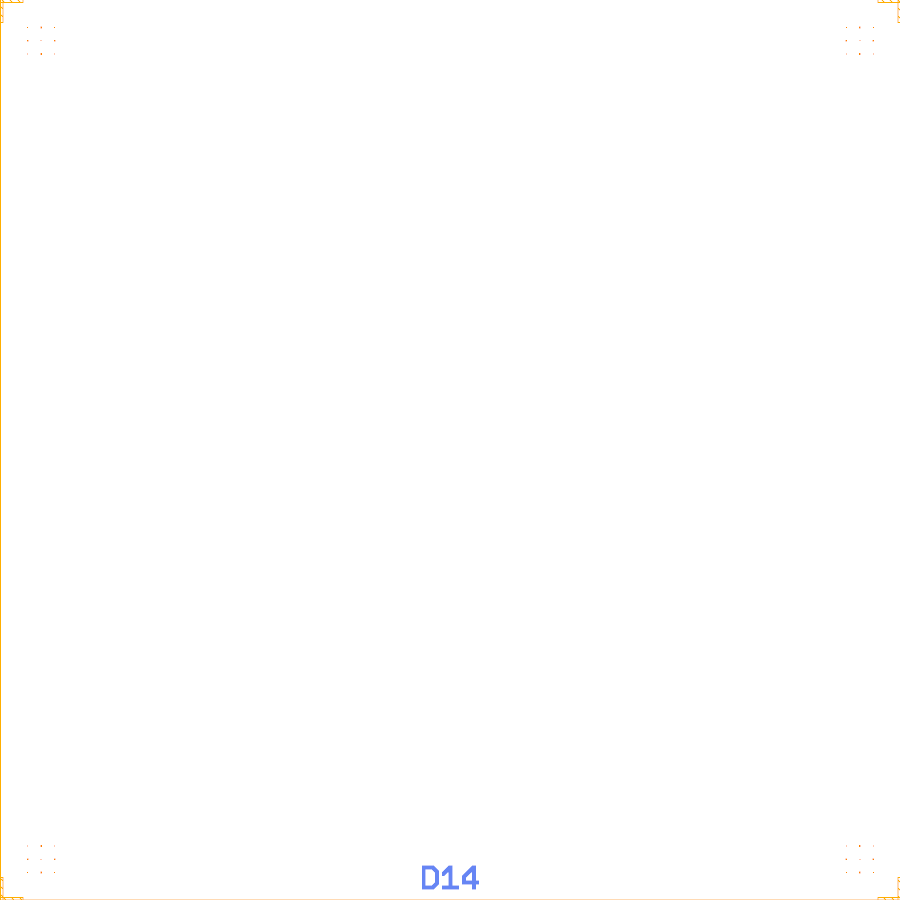

WindowsPath('build/legacy_steps/d14_two_feedline_resonator_1_frame.png')

In [5]:
d = Designer(ID, box=(0, 0, 10000, 10000), chip={"name_chip": "D14", "cheese": "chip"}, live=LIVE)
print(d.design.chip.box, d.design.pdk)
L.step_snapshot(d, "1_frame")

## 4 · Launchpads (PDK pad rule)

Eight Metal `LaunchpadWirebondDriven`s, two per edge at ±1.9 mm from the edge centre: the four on the left / right
edges carry the feedlines (lead 20 µm), the four on the bottom / top edges are unconnected in the source. The PDK
pad rule wants each outer etch **`pad_edge` = 100 µm** from its die edge (`get_pdk().frame.pad_edge`); the legacy
launchpads (taper tip 1.04 mm inside the die edge) already have it, as `L.edge_gaps` shows. The rule is written into
the design in step 7 (`C.pads_to_edge`, after the hangers exist).

pad etch → die edge (µm), legacy positions: {'LP_LB': 100.0, 'LP_LT': 100.0, 'LP_RB': 100.0, 'LP_RT': 100.0, 'LP_BL': 100.0, 'LP_BR': 100.0, 'LP_TL': 100.0, 'LP_TR': 100.0} | rule: 100.0


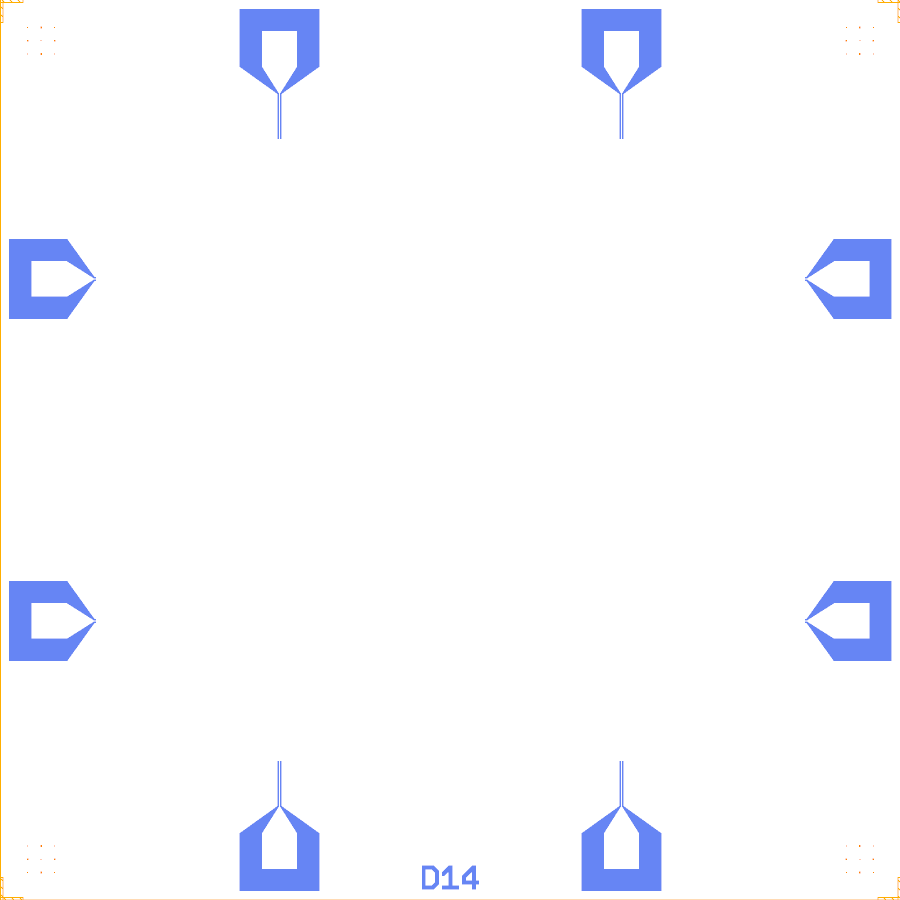

WindowsPath('build/legacy_steps/d14_two_feedline_resonator_2_pads.png')

In [6]:
lp = {}
with d.batch():
    for e, sx in (("L", -1), ("R", +1)):          # left / right: carry the feedlines
        for tb, sy in (("B", -1), ("T", +1)):
            lp[e + tb] = d.add(f"LP_{e}{tb}", "metal:LaunchpadWirebondDriven",
                               at=(X0 + sx * P["lp_inset"], Y0 + sy * P["lp_offset"]), rot=0 if sx < 0 else 180,
                               **{**LB.D14_LAUNCHPAD, "lead_length": "20um"})
    for tb, sy in (("B", -1), ("T", +1)):          # bottom / top: unconnected in the source
        for e, sx in (("L", -1), ("R", +1)):
            d.add(f"LP_{tb}{e}", "metal:LaunchpadWirebondDriven",
                  at=(X0 + sx * P["lp_offset"], Y0 + sy * P["lp_inset"]), rot=90 if sy < 0 else 270,
                  **LB.D14_LAUNCHPAD)
print("pad etch → die edge (µm), legacy positions:", L.edge_gaps(d), "| rule:", get_pdk().frame.pad_edge)
L.step_snapshot(d, "2_pads")

## 5 · Components: six Xmons and six open ends

On the bottom feedline each resonator starts at the claw of a `metal:TransmonCross` (the 12.0 claw; rotated 180°
above the line), placed so that its claw pin lands exactly where the open end would be; each draws the PDK
`Quantcore Junction` on its junction line and carries the same values for the LOM (`junction=`). On the top
feedline each resonator starts at a `metal:OpenToGround` (its open end). Positions follow the §5 plan.

PDK junction rule: Nb trilayer, Δ = 1.4 meV → I_c·R_n = πΔ/2e = 2.199 mV; PDK process R_n·A = 13500 Ω·µm² (J_c = 0.163 µA/µm²; nominal 0.5 × 0.6 µm → 45 kΩ, L_J 6.73 nH), C_J = 50 fF/µm² (R_n·A and C_J assumed by the PDK).


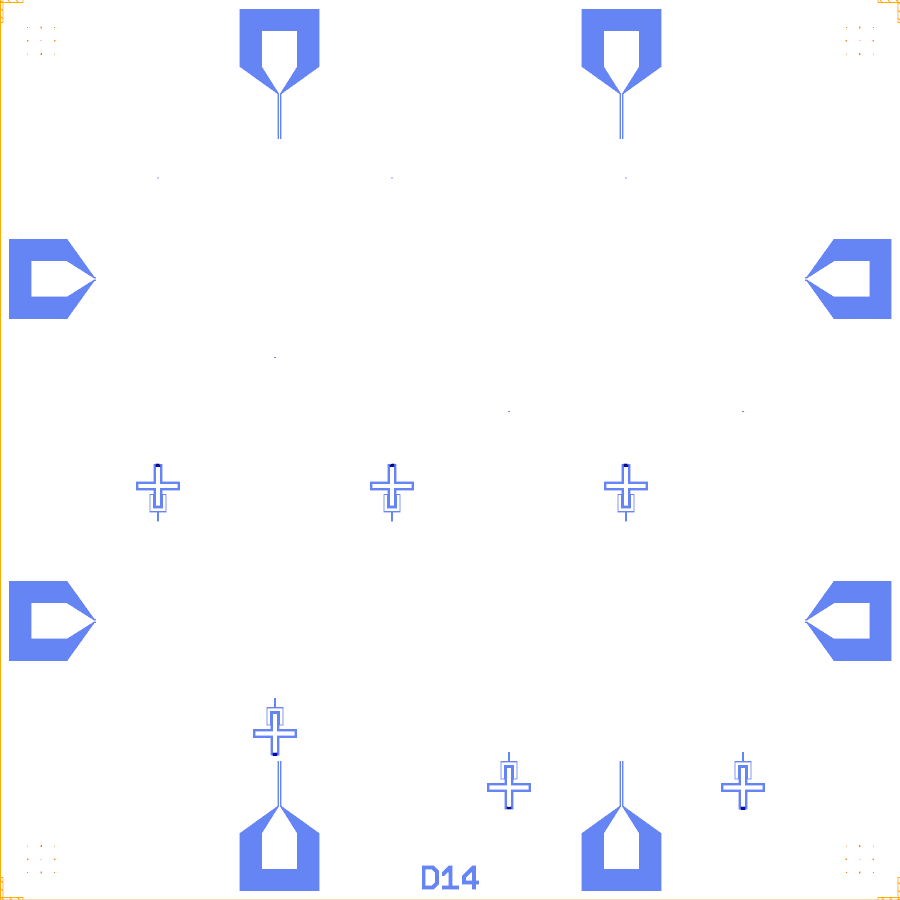

WindowsPath('build/legacy_steps/d14_two_feedline_resonator_3_components.png')

In [7]:
starts = {}
with d.batch():
    for tb, feed_y in (("T", +P["lp_offset"]), ("B", -P["lp_offset"])):
        for r in PLAN:
            i, s = r["i"], r["side"]
            y_end = Y0 + feed_y + s * P["res_gap"] + s * r["dy"]
            x_end = X0 + r["xc"]
            if tb == "B":   # the claw pin lands exactly where the open end would be
                starts[tb, i] = d.add(f"Q_B{i}", "metal:TransmonCross", at=(x_end, y_end + s * P["claw_offset"]),
                                      rot=180 if s > 0 else 0, junction=JUNCTION, **JJ, **LB.D14_XMON).a
            else:
                starts[tb, i] = d.add(f"open_T{i}", "metal:OpenToGround", at=(x_end, y_end), rot=90 if s > 0 else 270).open
print(L.rule_md())
L.step_snapshot(d, "3_components")

## 6 · Routes: two feedlines and twelve resonators

Each feedline (`FL_T`, `FL_B`, 20/12 µm) runs between its left and right launchpads. Each resonator runs from its
open end / Xmon claw straight towards the feedline at x = xc, over to the far end of its coupler, then 500 µm along
the feedline to the short: a qcc **hanger** end (`fl.hanger(s=…, length=500, ground_gap=3, end="short")`, 36 µm off
the feedline centre-line). `meander=` gives the legacy length (KQC picks the arm count). Then the targets (the
calibration frequencies) and the sim groups.

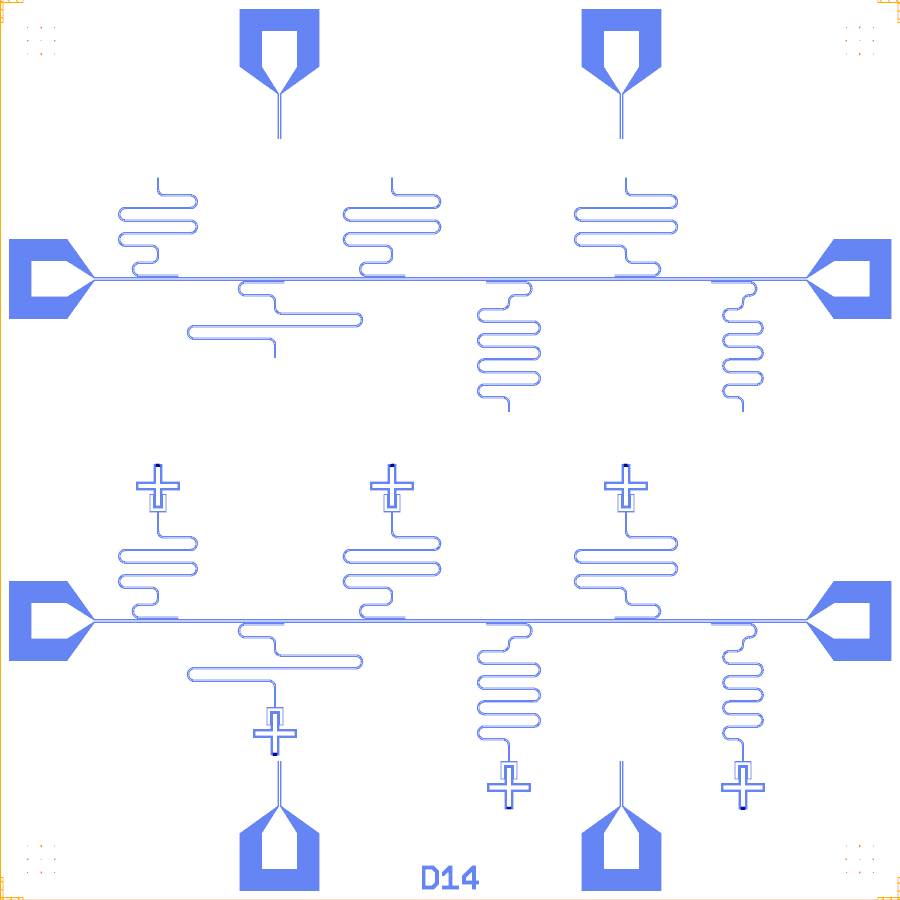

{'FL_T': 7880.0, 'FL_B': 7880.0, 'R_T0': 4910.0, 'R_T1': 5325.0, 'R_T2': 5815.0, 'R_T3': 6405.0, 'R_T4': 6095.0, 'R_T5': 4550.0, 'R_B0': 4910.0, 'R_B1': 5325.0, 'R_B2': 5815.0, 'R_B3': 6405.0, 'R_B4': 6095.0, 'R_B5': 4550.0}


In [8]:
with d.batch():
    fl = {tb: d.route(f"FL_{tb}", lp["L" + tb].tie, lp["R" + tb].tie, a=20, b=12) for tb in ("T", "B")}
    for tb, feed_y in (("T", +P["lp_offset"]), ("B", -P["lp_offset"])):
        for r in PLAN:
            i, s, dirx = r["i"], r["side"], r["dirx"]
            y_short = Y0 + feed_y + s * P["res_gap"]
            x_end, x_short = X0 + r["xc"], X0 + r["x_short"]
            hanger = fl[tb].hanger(s=x_short + dirx * P["coupler"] / 2 - FL_X0, length=P["coupler"],
                                   side="left" if s > 0 else "right", ground_gap=3,
                                   direction="forward" if dirx < 0 else "backward", end="short")
            y_turn = y_short + s * (2 * R_BEND + 5)
            d.route(f"R_{tb}{i}", starts[tb, i], hanger, meander=r["L"], a=10, b=6, r=R_BEND,
                    nodes=[(x_end, y_turn), (x_short + dirx * P["coupler"], y_turn)])
d.targets(**{f"R_{tb}{r['i']}": {"f_GHz": r["f"]} for tb in ("T", "B") for r in PLAN})
for i in range(6):
    d.sim_group(f"Q_B{i}_R_B{i}", [f"Q_B{i}", f"R_B{i}"], margin_um=300, analyses=["q3d_cmatrix", "eigenmode_epr"])
    d.sim_group(f"R_T{i}", [f"open_T{i}", f"R_T{i}"], margin_um=300, analyses=["q3d_cmatrix", "eigenmode_epr"])
L.step_snapshot(d, "4_routes")
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})

## 7 · Pad rule, the source's cheese, and centring

**Pad rule.** `C.pads_to_edge(d)` pins the hangers (`near=` their current coupler centre) and gives every launchpad
`edge="auto"`; the legacy pads are already at 100 µm, so nothing moves (the gaps are printed again).

**Cheese — the source's holes and the PDK cheese.** The source's §8 flux holes beside both feedlines: 5 µm squares on a 25 µm pitch in
rows parallel to the feedlines, each hole kept only if it lies ≥ 30 µm from every etched edge of the built chip (the
legacy filter, `LB.flux_hole_runs`), drawn as `FluxHoleArray` runs on 1/0. They stay as drawn; the chip's `cheese: "chip"` (step 3) adds the PDK squares over the rest of the die, at least 4 µm from the 3/0 keep-outs (which cover the hole runs too), so no PDK hole touches a structure or a flux hole.

**Centring.** `L.center_circuit` (each axis only if > 50 µm off); then the design is saved.

pad etch → die edge (µm): {'LP_LB': 100.0, 'LP_LT': 100.0, 'LP_RB': 100.0, 'LP_RT': 100.0, 'LP_BL': 100.0, 'LP_BR': 100.0, 'LP_TL': 100.0, 'LP_TR': 100.0}


984 flux holes in 16 runs | centring shift (µm): (0.0, 0.0) | <Designer d14_two_feedline_resonator: 36 instances, 14 routes, live=False> → examples\designs\legacy\d14_two_feedline_resonator.json


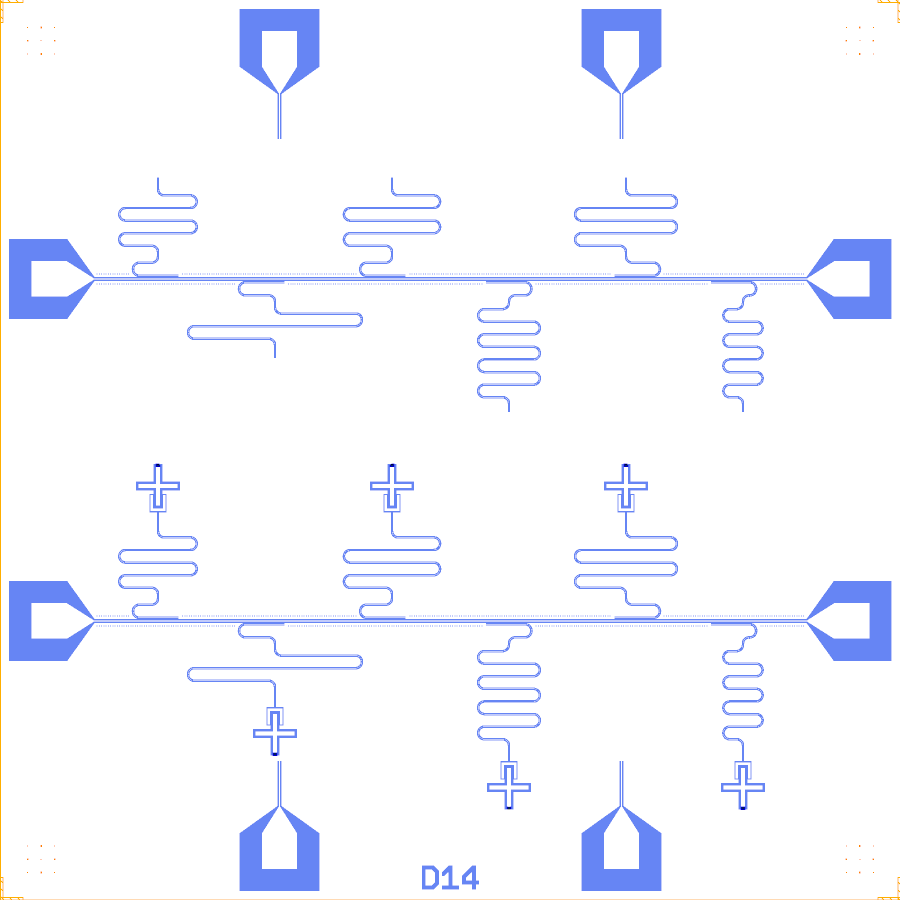

device ID block (µm): (4650,100;5350,400)


In [9]:
moved = C.pads_to_edge(d)                         # pins the hangers first; the legacy pads are already at 100 µm
print("pad etch → die edge (µm):", L.edge_gaps(d))
d.show()
off = 22 + P["cheese_clear"] + P["cheese_size"] / 2
rows = [("x", Y0 + fy + sg * off, X0 - P["lp_inset"], X0 + P["lp_inset"])
        for fy in (P["lp_offset"], -P["lp_offset"]) for sg in (+1, -1)]
runs = LB.flux_hole_runs(d, rows, P["cheese_size"], P["cheese_pitch"], P["cheese_clear"])
with d.batch():
    for k, (x, y, nx, ny) in enumerate(runs):
        d.add(f"FH{k}", "FluxHoleArray", at=(x, y), hole_size=P["cheese_size"], pitch_x=P["cheese_pitch"],
              pitch_y=P["cheese_pitch"], nx=nx, ny=ny)
SHIFT = L.center_circuit(d)
DESIGN = d.save(OUT / f"{ID}.json")
print(f"{sum(n * m for *_, n, m in runs)} flux holes in {len(runs)} runs | centring shift (µm):", SHIFT, "|", d, "→", DESIGN)
L.step_snapshot(d, "5_holes")
print("device ID block (µm):", device_id_block(d.result))

## 8 · DRC

`d.drc()` builds the chip and checks it: **errors** (overlapping etch of unrelated cells, ports not landing,
parts outside the chip, a route looping over itself or running over a component) must be fixed; **warnings** are
reported for a person to judge (a dangling open end, two cells' bounding boxes touching); **PDK design warnings**
(`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`) flag values outside the PDK margins — they are never retuned for, only
listed. `C.pdk_report(d)` summarises the PDK checks: cheese source, content centring (free text labels left out),
junction types and the design warnings.

Expected (this run): zero errors and no keep-out violations (the device ID `D14` keeps its bottom-centre slot,
(4650, 100)–(5350, 400) µm). The 24 warnings are all `dangling_port`, all by design: every launchpad's `in` (8: the
wire-bond pad itself, bonded, never routed), the `tie` of the four top / bottom launchpads (4: unconnected in the
source) and each Xmon's `squid_a` / `squid_b` (12: junction attachment points of the Metal wrapper, not route ends).
No PDK design warnings (pads at 100 µm, junctions at 45 kΩ). `pdk_report`: cheese "PDK cheese over the whole die (drawn in the build)",
content centre (+0, +0) µm, junction types `Quantcore Junction` × 6.

In [10]:
drc = d.drc()
print(drc)
display(Markdown(C.pdk_report(d)))

warning dangling_port LP_BL.in is not connected (no route or snap)
warning dangling_port LP_BL.tie is not connected (no route or snap)
warning dangling_port LP_BR.in is not connected (no route or snap)
warning dangling_port LP_BR.tie is not connected (no route or snap)
warning dangling_port LP_LB.in is not connected (no route or snap)
warning dangling_port LP_LT.in is not connected (no route or snap)
warning dangling_port LP_RB.in is not connected (no route or snap)
warning dangling_port LP_RT.in is not connected (no route or snap)
warning dangling_port LP_TL.in is not connected (no route or snap)
warning dangling_port LP_TL.tie is not connected (no route or snap)
warning dangling_port LP_TR.in is not connected (no route or snap)
warning dangling_port LP_TR.tie is not connected (no route or snap)
warning dangling_port Q_B0.squid_a is not connected (no route or snap)
warning dangling_port Q_B0.squid_b is not connected (no route or snap)
warning dangling_port Q_B1.squid_a is not connecte

| check | value |
|---|---|
| cheese | the original design's own (or none) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Junction × 6 |
| PDK design warnings | 0 (none) |

## 9 · Netlist and LOM

Each feedline is one node (with both launchpad pads) and a 50 Ω port at each end. A top resonator is a λ/4 `TLres`
from its open-end node to ground plus a HANGER κ element to the feedline node. A bottom resonator: Xmon island (C, JJ
to ground) — C_g — claw node — λ/4 `R_Bi` — HANGER to `FL_B`. Unconnected launchpads keep their own pad node with a
50 Ω port. The "unconnected ports" are the pads' `in` (the bond pad) and the four unrouted `tie`s; every one of them
maps to a pad node. The flux holes have no circuit role.

In [11]:
lb = d.lom()
C.show_netlist(lb)
print(C.lom_summary(lb))

**25 nodes · 56 branches · 0 controls · 12 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `FL_B` | `FL_B`, `LP_LB.pad`, `LP_RB.pad` |
| `FL_T` | `FL_T`, `LP_LT.pad`, `LP_RT.pad` |
| `LP_BL.pad` | `LP_BL.pad` |
| `LP_BR.pad` | `LP_BR.pad` |
| `LP_TL.pad` | `LP_TL.pad` |
| `LP_TR.pad` | `LP_TR.pad` |
| `open_T0.end` | `open_T0.end` |
| `open_T1.end` | `open_T1.end` |
| `open_T2.end` | `open_T2.end` |
| `open_T3.end` | `open_T3.end` |
| `open_T4.end` | `open_T4.end` |
| `open_T5.end` | `open_T5.end` |
| `Q_B0` | `Q_B0.island` |
| `Q_B0.a` | `Q_B0.a` |
| `Q_B1` | `Q_B1.island` |
| `Q_B1.a` | `Q_B1.a` |
| `Q_B2` | `Q_B2.island` |
| `Q_B2.a` | `Q_B2.a` |
| `Q_B3` | `Q_B3.island` |
| `Q_B3.a` | `Q_B3.a` |
| `Q_B4` | `Q_B4.island` |
| `Q_B4.a` | `Q_B4.a` |
| `Q_B5` | `Q_B5.island` |
| `Q_B5.a` | `Q_B5.a` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_LP_LB` | R | `FL_B` – `gnd` | 50 Ω |
| `Port_LP_LT` | R | `FL_T` – `gnd` | 50 Ω |
| `Port_LP_RB` | R | `FL_B` – `gnd` | 50 Ω |
| `Port_LP_RT` | R | `FL_T` – `gnd` | 50 Ω |
| `Port_LP_BL` | R | `LP_BL.pad` – `gnd` | 50 Ω |
| `Port_LP_BR` | R | `LP_BR.pad` – `gnd` | 50 Ω |
| `Port_LP_TL` | R | `LP_TL.pad` – `gnd` | 50 Ω |
| `Port_LP_TR` | R | `LP_TR.pad` – `gnd` | 50 Ω |
| `C_Q_B0` | C | `Q_B0` – `gnd` | 120 fF |
| `J_Q_B0` | JJ | `Q_B0` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q_B0_a` | C | `Q_B0` – `Q_B0.a` | 5.2 fF |
| `Cc_Q_B0_a` | C | `Q_B0.a` – `gnd` | 121 fF |
| `C_Q_B1` | C | `Q_B1` – `gnd` | 120 fF |
| `J_Q_B1` | JJ | `Q_B1` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q_B1_a` | C | `Q_B1` – `Q_B1.a` | 5.2 fF |
| `Cc_Q_B1_a` | C | `Q_B1.a` – `gnd` | 121 fF |
| `C_Q_B2` | C | `Q_B2` – `gnd` | 120 fF |
| `J_Q_B2` | JJ | `Q_B2` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q_B2_a` | C | `Q_B2` – `Q_B2.a` | 5.2 fF |
| `Cc_Q_B2_a` | C | `Q_B2.a` – `gnd` | 121 fF |
| `C_Q_B3` | C | `Q_B3` – `gnd` | 120 fF |
| `J_Q_B3` | JJ | `Q_B3` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q_B3_a` | C | `Q_B3` – `Q_B3.a` | 5.2 fF |
| `Cc_Q_B3_a` | C | `Q_B3.a` – `gnd` | 121 fF |
| `C_Q_B4` | C | `Q_B4` – `gnd` | 120 fF |
| `J_Q_B4` | JJ | `Q_B4` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q_B4_a` | C | `Q_B4` – `Q_B4.a` | 5.2 fF |
| `Cc_Q_B4_a` | C | `Q_B4.a` – `gnd` | 121 fF |
| `C_Q_B5` | C | `Q_B5` – `gnd` | 120 fF |
| `J_Q_B5` | JJ | `Q_B5` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q_B5_a` | C | `Q_B5` – `Q_B5.a` | 5.2 fF |
| `Cc_Q_B5_a` | C | `Q_B5.a` – `gnd` | 121 fF |
| `R_B0` | TLres | `Q_B0.a` – `gnd` | lambda/4, 4910 µm, 6.417 GHz |
| `K_R_B0` | HANGER | `Q_B0.a` – `FL_B` | κ 0.83 MHz (L 500 µm) |
| `R_B1` | TLres | `Q_B1.a` – `gnd` | lambda/4, 5325 µm, 5.917 GHz |
| `K_R_B1` | HANGER | `Q_B1.a` – `FL_B` | κ 0.652 MHz (L 500 µm) |
| `R_B2` | TLres | `Q_B2.a` – `gnd` | lambda/4, 5815 µm, 5.419 GHz |
| `K_R_B2` | HANGER | `Q_B2.a` – `FL_B` | κ 0.501 MHz (L 500 µm) |
| `R_B3` | TLres | `Q_B3.a` – `gnd` | lambda/4, 6405 µm, 4.919 GHz |
| `K_R_B3` | HANGER | `Q_B3.a` – `FL_B` | κ 0.375 MHz (L 500 µm) |
| `R_B4` | TLres | `Q_B4.a` – `gnd` | lambda/4, 6095 µm, 5.170 GHz |
| `K_R_B4` | HANGER | `Q_B4.a` – `FL_B` | κ 0.435 MHz (L 500 µm) |
| `R_B5` | TLres | `Q_B5.a` – `gnd` | lambda/4, 4550 µm, 6.925 GHz |
| `K_R_B5` | HANGER | `Q_B5.a` – `FL_B` | κ 1.04 MHz (L 500 µm) |
| `R_T0` | TLres | `open_T0.end` – `gnd` | lambda/4, 4910 µm, 6.417 GHz |
| `K_R_T0` | HANGER | `open_T0.end` – `FL_T` | κ 0.83 MHz (L 500 µm) |
| `R_T1` | TLres | `open_T1.end` – `gnd` | lambda/4, 5325 µm, 5.917 GHz |
| `K_R_T1` | HANGER | `open_T1.end` – `FL_T` | κ 0.652 MHz (L 500 µm) |
| `R_T2` | TLres | `open_T2.end` – `gnd` | lambda/4, 5815 µm, 5.419 GHz |
| `K_R_T2` | HANGER | `open_T2.end` – `FL_T` | κ 0.501 MHz (L 500 µm) |
| `R_T3` | TLres | `open_T3.end` – `gnd` | lambda/4, 6405 µm, 4.919 GHz |
| `K_R_T3` | HANGER | `open_T3.end` – `FL_T` | κ 0.375 MHz (L 500 µm) |
| `R_T4` | TLres | `open_T4.end` – `gnd` | lambda/4, 6095 µm, 5.170 GHz |
| `K_R_T4` | HANGER | `open_T4.end` – `FL_T` | κ 0.435 MHz (L 500 µm) |
| `R_T5` | TLres | `open_T5.end` – `gnd` | lambda/4, 4550 µm, 6.925 GHz |
| `K_R_T5` | HANGER | `open_T5.end` – `FL_T` | κ 1.04 MHz (L 500 µm) |

**Unconnected ports:** `LP_BL.in`, `LP_BL.tie`, `LP_BR.in`, `LP_BR.tie`, `LP_LB.in`, `LP_LT.in`, `LP_RB.in`, `LP_RT.in`, `LP_TL.in`, `LP_TL.tie`, `LP_TR.in`, `LP_TR.tie`

{'nodes': 24, 'branches': 56, 'controls': 0, 'unconnected': 12}


## 10 · LOM simulation

Each qubit / resonator pair and each bare top resonator on its own (they share only the feedline, kept as a 25 Ω
load): QuCat normal modes and κ, then QuTiP-dressed f_q, α, f_r, χ. Targets (in brackets) are the legacy design
frequencies, which come from a calibration of *bare* resonators. The second table compares the LOM's bare λ/4
frequency with the legacy calibration at the same length.

In [12]:
groups = {f"Q_B{i}+R_B{i}": [f"Q_B{i}", f"R_B{i}"] for i in range(6)}
groups |= {f"R_T{i}": [f"open_T{i}", f"R_T{i}"] for i in range(6)}
results = C.simulate_groups(d, groups)
display(Markdown(C.groups_md(results, d.data["targets"])))
a, b = LB.d14_calibration()
rows = ["| resonator | length (µm) | target (GHz) | legacy calibration (GHz) | LOM bare λ/4 (GHz) | LOM loaded (GHz) |",
        "|---|---|---|---|---|---|"]
for tb in ("T", "B"):
    for r in PLAN:
        name = f"R_{tb}{r['i']}"
        res = results[f"R_T{r['i']}" if tb == "T" else f"Q_B{r['i']}+R_B{r['i']}"]
        rows.append(f"| {name} | {r['L']:.0f} | {r['f']:.2f} | {1 / (a * r['L'] + b):.3f} | "
                    f"{lb.model.branches[name].value['f_GHz']:.3f} | {res.params.get(f'{name}.f_GHz', float('nan')):.3f} |")
display(Markdown("\n".join(rows)))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q_B0+R_B0 | Q_B0 | 5.032 | -144.3 | R_B0 | 5.4773 (6.5) | 0.428 | -3.33 |
| Q_B1+R_B1 | Q_B1 | 5.1264 | -345.9 | R_B1 | 5.011 (6) | 0.288 | 111 |
| Q_B2+R_B2 | Q_B2 | 5.0445 | -138.5 | R_B2 | 4.7145 (5.5) | 0.285 | -9.1 |
| Q_B3+R_B3 | Q_B3 | 5.0406 | -146.5 | R_B3 | 4.3319 (5) | 0.225 | -1.12 |
| Q_B4+R_B4 | Q_B4 | 5.0419 | -145 | R_B4 | 4.5254 (5.25) | 0.255 | -2.66 |
| Q_B5+R_B5 | Q_B5 | 5.0344 | -146.3 | R_B5 | 5.845 (7) | 0.525 | -1.35 |
| R_T0 | – | – | – | R_T0 | 6.3569 (6.5) | 0.799 | – |
| R_T1 | – | – | – | R_T1 | 5.8658 (6) | 0.629 | – |
| R_T2 | – | – | – | R_T2 | 5.3754 (5.5) | 0.485 | – |
| R_T3 | – | – | – | R_T3 | 4.8838 (5) | 0.365 | – |
| R_T4 | – | – | – | R_T4 | 5.1303 (5.25) | 0.422 | – |
| R_T5 | – | – | – | R_T5 | 6.8549 (7) | 1 | – |

| resonator | length (µm) | target (GHz) | legacy calibration (GHz) | LOM bare λ/4 (GHz) | LOM loaded (GHz) |
|---|---|---|---|---|---|
| R_T0 | 4910 | 6.50 | 6.497 | 6.417 | 6.357 |
| R_T1 | 5325 | 6.00 | 5.999 | 5.917 | 5.866 |
| R_T2 | 5815 | 5.50 | 5.500 | 5.419 | 5.375 |
| R_T3 | 6405 | 5.00 | 5.000 | 4.919 | 4.884 |
| R_T4 | 6095 | 5.25 | 5.251 | 5.170 | 5.130 |
| R_T5 | 4550 | 7.00 | 7.002 | 6.925 | 6.855 |
| R_B0 | 4910 | 6.50 | 6.497 | 6.417 | 5.477 |
| R_B1 | 5325 | 6.00 | 5.999 | 5.917 | 5.011 |
| R_B2 | 5815 | 5.50 | 5.500 | 5.419 | 4.715 |
| R_B3 | 6405 | 5.00 | 5.000 | 4.919 | 4.332 |
| R_B4 | 6095 | 5.25 | 5.251 | 5.170 | 4.525 |
| R_B5 | 4550 | 7.00 | 7.002 | 6.925 | 5.845 |

**Reading the numbers** (LOM of this run). The LOM's bare λ/4 sits 1.1–1.3 % (≈ 80 MHz) below the legacy calibration on
all twelve lengths, and the top (open-ended) resonators land 0.12–0.15 GHz below their targets once the hanger loads
them (6.36, 5.87, 5.38, 4.88, 5.13, 6.85 GHz for 6.5 … 7.0). On the bottom feedline the Xmon claw (≈ 125 fF,
analytic estimate) pulls each resonator 0.6–1.1 GHz below its bare value (5.48, 5.01, 4.71, 4.33, 4.53, 5.85 GHz):
the legacy lengths were simulated without the claws (#12), so the two rows do *not* sit at the same frequencies. The
Xmons sit at 5.03–5.13 GHz (R_n 45 kΩ): **Q_B1/R_B1 (5.13 / 5.01 GHz, χ 111 MHz) hybridise**, Q_B2/R_B2 (χ −9.1
MHz) is close; the others are dispersive. Both the claw capacitance and the junction values are estimates; the FEM
C-matrix (step 11) replaces the capacitances.

## 11 · FEM: send the job

Each sim group is cut out of the chip (its instances plus a margin of ground), with the PDK stack (sapphire
650 µm, ε_r 10.25) and **without cheese** (simulation exports never have it), and written as a job folder
under `build/jobs/` (`C.export_sims` → `build_simulation` + `export_job`): a Q3D C-matrix job by default,
`analysis="eigenmode_epr"` for the eigenmode / EPR job. With `RUN_FEM = True` and AEDT 2024 R1 (v241) or
newer on this machine, `L.fem_send` solves each job in a **new batch, non-graphical** AEDT
(`sim_tools.hfss.solve_job`) — it never touches an AEDT window you have open. The default here is
`False`: export only.

Here: one Q3D C-matrix and one eigenmode / EPR job per sim group (cut out with a 300 µm margin): each Xmon group
has the junction port and the claw's waveguide port, with nets `Q_Bi.island` and `Q_Bi.a`; each top resonator group
has the open end's waveguide port. Simulation exports never carry cheese: the flux holes are left out.

In [13]:
RUN_FEM = False                       # True: solve the exported jobs here (AEDT 2024 R1+, batch)
jobs = C.export_sims(DESIGN)
display(Markdown(C.jobs_md(jobs)))
display(Markdown(L.fem_send(jobs, run=RUN_FEM)))

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q_B0_R_B0 | `build/jobs/d14_two_feedline_resonator_Q_B0_R_B0_q3d_cmatrix` | 1 · junction · `Q_B0.junction`<br>2 · waveguide · `Q_B0.a` | `Q_B0.island`, `Q_B0.a` |
| R_T0 | `build/jobs/d14_two_feedline_resonator_R_T0_q3d_cmatrix` | 1 · waveguide · `open_T0.open` | `open_T0.open` |
| Q_B1_R_B1 | `build/jobs/d14_two_feedline_resonator_Q_B1_R_B1_q3d_cmatrix` | 1 · junction · `Q_B1.junction`<br>2 · waveguide · `Q_B1.a` | `Q_B1.island`, `Q_B1.a` |
| R_T1 | `build/jobs/d14_two_feedline_resonator_R_T1_q3d_cmatrix` | 1 · waveguide · `open_T1.open` | `open_T1.open` |
| Q_B2_R_B2 | `build/jobs/d14_two_feedline_resonator_Q_B2_R_B2_q3d_cmatrix` | 1 · junction · `Q_B2.junction`<br>2 · waveguide · `Q_B2.a` | `Q_B2.island`, `Q_B2.a` |
| R_T2 | `build/jobs/d14_two_feedline_resonator_R_T2_q3d_cmatrix` | 1 · waveguide · `open_T2.open` | `open_T2.open` |
| Q_B3_R_B3 | `build/jobs/d14_two_feedline_resonator_Q_B3_R_B3_q3d_cmatrix` | 1 · junction · `Q_B3.junction`<br>2 · waveguide · `Q_B3.a` | `Q_B3.island`, `Q_B3.a` |
| R_T3 | `build/jobs/d14_two_feedline_resonator_R_T3_q3d_cmatrix` | 1 · waveguide · `open_T3.open` | `open_T3.open` |
| Q_B4_R_B4 | `build/jobs/d14_two_feedline_resonator_Q_B4_R_B4_q3d_cmatrix` | 1 · junction · `Q_B4.junction`<br>2 · waveguide · `Q_B4.a` | `Q_B4.island`, `Q_B4.a` |
| R_T4 | `build/jobs/d14_two_feedline_resonator_R_T4_q3d_cmatrix` | 1 · waveguide · `open_T4.open` | `open_T4.open` |
| Q_B5_R_B5 | `build/jobs/d14_two_feedline_resonator_Q_B5_R_B5_q3d_cmatrix` | 1 · junction · `Q_B5.junction`<br>2 · waveguide · `Q_B5.a` | `Q_B5.island`, `Q_B5.a` |
| R_T5 | `build/jobs/d14_two_feedline_resonator_R_T5_q3d_cmatrix` | 1 · waveguide · `open_T5.open` | `open_T5.open` |

AEDT on this machine: `C:\Program Files\AnsysEM\v241\Win64\ansysedt.exe` (v241)

`RUN_FEM = False`: 12 job(s) exported, none solved. Set `RUN_FEM = True` to solve them here (batch, non-graphical), or run `qcc sim run <job>` on a machine with AEDT 2024 R1+.

## 12 · Bring the results back

A solved job leaves `results/results.json` in its folder. `fill(model, DESIGN, job)` then replaces the LOM's
component estimates by the FEM C-matrix, matched by net name (the net names are the ones in the job table
above), and the LOM is simulated again with them. `L.fem_bring_back` does this for every job that has
results and says which have none yet.

No job has been solved yet, so the cell says so. With results, the C-matrix would replace the claw estimate
(≈ 125 fF) that pulls the bottom row below its targets.

In [14]:
display(Markdown(L.fem_bring_back(d, DESIGN, jobs, groups=None)))

No FEM results yet for 12 job(s) (`build/jobs/d14_two_feedline_resonator_Q_B0_R_B0_q3d_cmatrix`, `build/jobs/d14_two_feedline_resonator_R_T0_q3d_cmatrix`, `build/jobs/d14_two_feedline_resonator_Q_B1_R_B1_q3d_cmatrix`, `build/jobs/d14_two_feedline_resonator_R_T1_q3d_cmatrix`, …). After a solve each job holds `results/results.json`; this cell then fills the LOM with the extracted C-matrix (`fill(model, DESIGN, job)`) and shows the estimate next to the FEM value per capacitance, and f_q / α / f_r / χ re-simulated with them.

## 13 · Iterate: change one property and re-simulate

Q_B1 sits on its loaded resonator R_B1 (step 10). A copy moves Q_B1's junction to the low end of the PDK window,
**R_n 40 kΩ** (`L.lj_for_rn(40e3)`, and the drawn cell's `lj_nH`): L_J falls by 11 %, f_q rises by ≈ 6 %, away
from R_B1. The copy is not saved; detuning Q_B1 (or retuning the bottom-row lengths for the claw, #12) is a user
decision.

In [15]:
d2 = Designer.load(DESIGN, live=False, verbose=False)      # a copy of the saved design
J40 = L.lj_for_rn(40e3)
d2["Q_B1"].set(junction=J40, junction_params={"lj_nH": J40["Lj_nH"]})
after = C.simulate_groups(d2, {"Q_B1+R_B1": groups["Q_B1+R_B1"]})["Q_B1+R_B1"]
print("Q_B1 junction:", JUNCTION, "→", J40)
display(Markdown(L.compare_md(results["Q_B1+R_B1"], after,
                              keys=["Q_B1.f_q_GHz", "Q_B1.alpha_MHz", "R_B1.f_GHz", "R_B1.chi_MHz"],
                              label=("R_n 45 kΩ", "R_n 40 kΩ"))))

Q_B1 junction: {'Lj_nH': 6.7344, 'Cj_fF': 15.0} → {'Lj_nH': 5.9862, 'Cj_fF': 16.875}


| parameter | R_n 45 kΩ | R_n 40 kΩ | Δ |
|---|---|---|---|
| `Q_B1.f_q_GHz` | 5.1264 | 5.329 | +0.2026 |
| `Q_B1.alpha_MHz` | -345.9 | -120.63 | +225.3 |
| `R_B1.f_GHz` | 5.011 | 5.0883 | +0.07735 |
| `R_B1.chi_MHz` | 110.89 | -24.011 | -134.9 |

## 14 · Build and export

The design is saved as JSON (`DESIGN`, step 7): it is the source of truth — the layout, the netlist, the
FEM jobs and the mask are all made from it. The **fab mask** (`export_fab`) keeps only the PDK fab layers
(1/0 etch, 2/0 + 4/0 junction fingers, 3/0 second-metal keep-out, 50–53/0 spacer, 100/0 boundary, 1000/0 +
1001/0 markers), rounds the corners (radius ∝ each polygon's shortest dimension) and keeps the build's
cheese; every cheese hole of 1/0 is also on 3/0. **Simulation exports** never carry cheese; they drop airbridges
unless asked (`build_simulation(..., airbridges=True)`); the legacy chips have none.

Here: `cheese=True` (the default) keeps the build's cheese: the PDK squares over the whole die (`cheese_source` "build") and the source's flux holes, which are part of 1/0 (drawn by `FluxHoleArray`).

The same from a shell:

```
qcc build examples/designs/legacy/d14_two_feedline_resonator.json                    # layout → build/d14_two_feedline_resonator.oas
qcc mask  examples/designs/legacy/d14_two_feedline_resonator.json          # fab mask with the PDK rules
qcc sim build examples/designs/legacy/d14_two_feedline_resonator.json -g Q_B0_R_B0 -a q3d_cmatrix   # one FEM job (step 11)
qcc sim run build/jobs/d14_two_feedline_resonator_Q_B0_R_B0_q3d_cmatrix              # solve it (AEDT 2024 R1+)
```

In [16]:
display(Markdown(L.fab_md(d)))

Fab mask: `build/d14_two_feedline_resonator_fab.oas` · cheese source **original** (0 PDK-band holes) · corner rounding on

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 1011 |
| 2/0 | JJ_STRAIGHT | 6 |
| 3/0 | M3 | 9 |
| 4/0 | JJ_BENT | 6 |
| 50/0 | HSQ | 12 |
| 51/0 | SPACER_1 | 12 |
| 52/0 | SPACER_2 | 12 |
| 53/0 | SPACER_3 | 12 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

## 15 · Snapshots and comparison with the legacy geometry

The full chip, then the legacy Metal GUI view (from the legacy notebook's own output,
`docs/images/designs/legacy/d14_two_feedline_resonator_legacy.png`) for comparison, zooms on an Xmon, its junction
and a coupler with the flux holes, and the resonator extents against the legacy printout (§7 of the source,
centre-line extents; the rebuilt ones are the gap outline shrunk by a/2 + b = 11 µm).

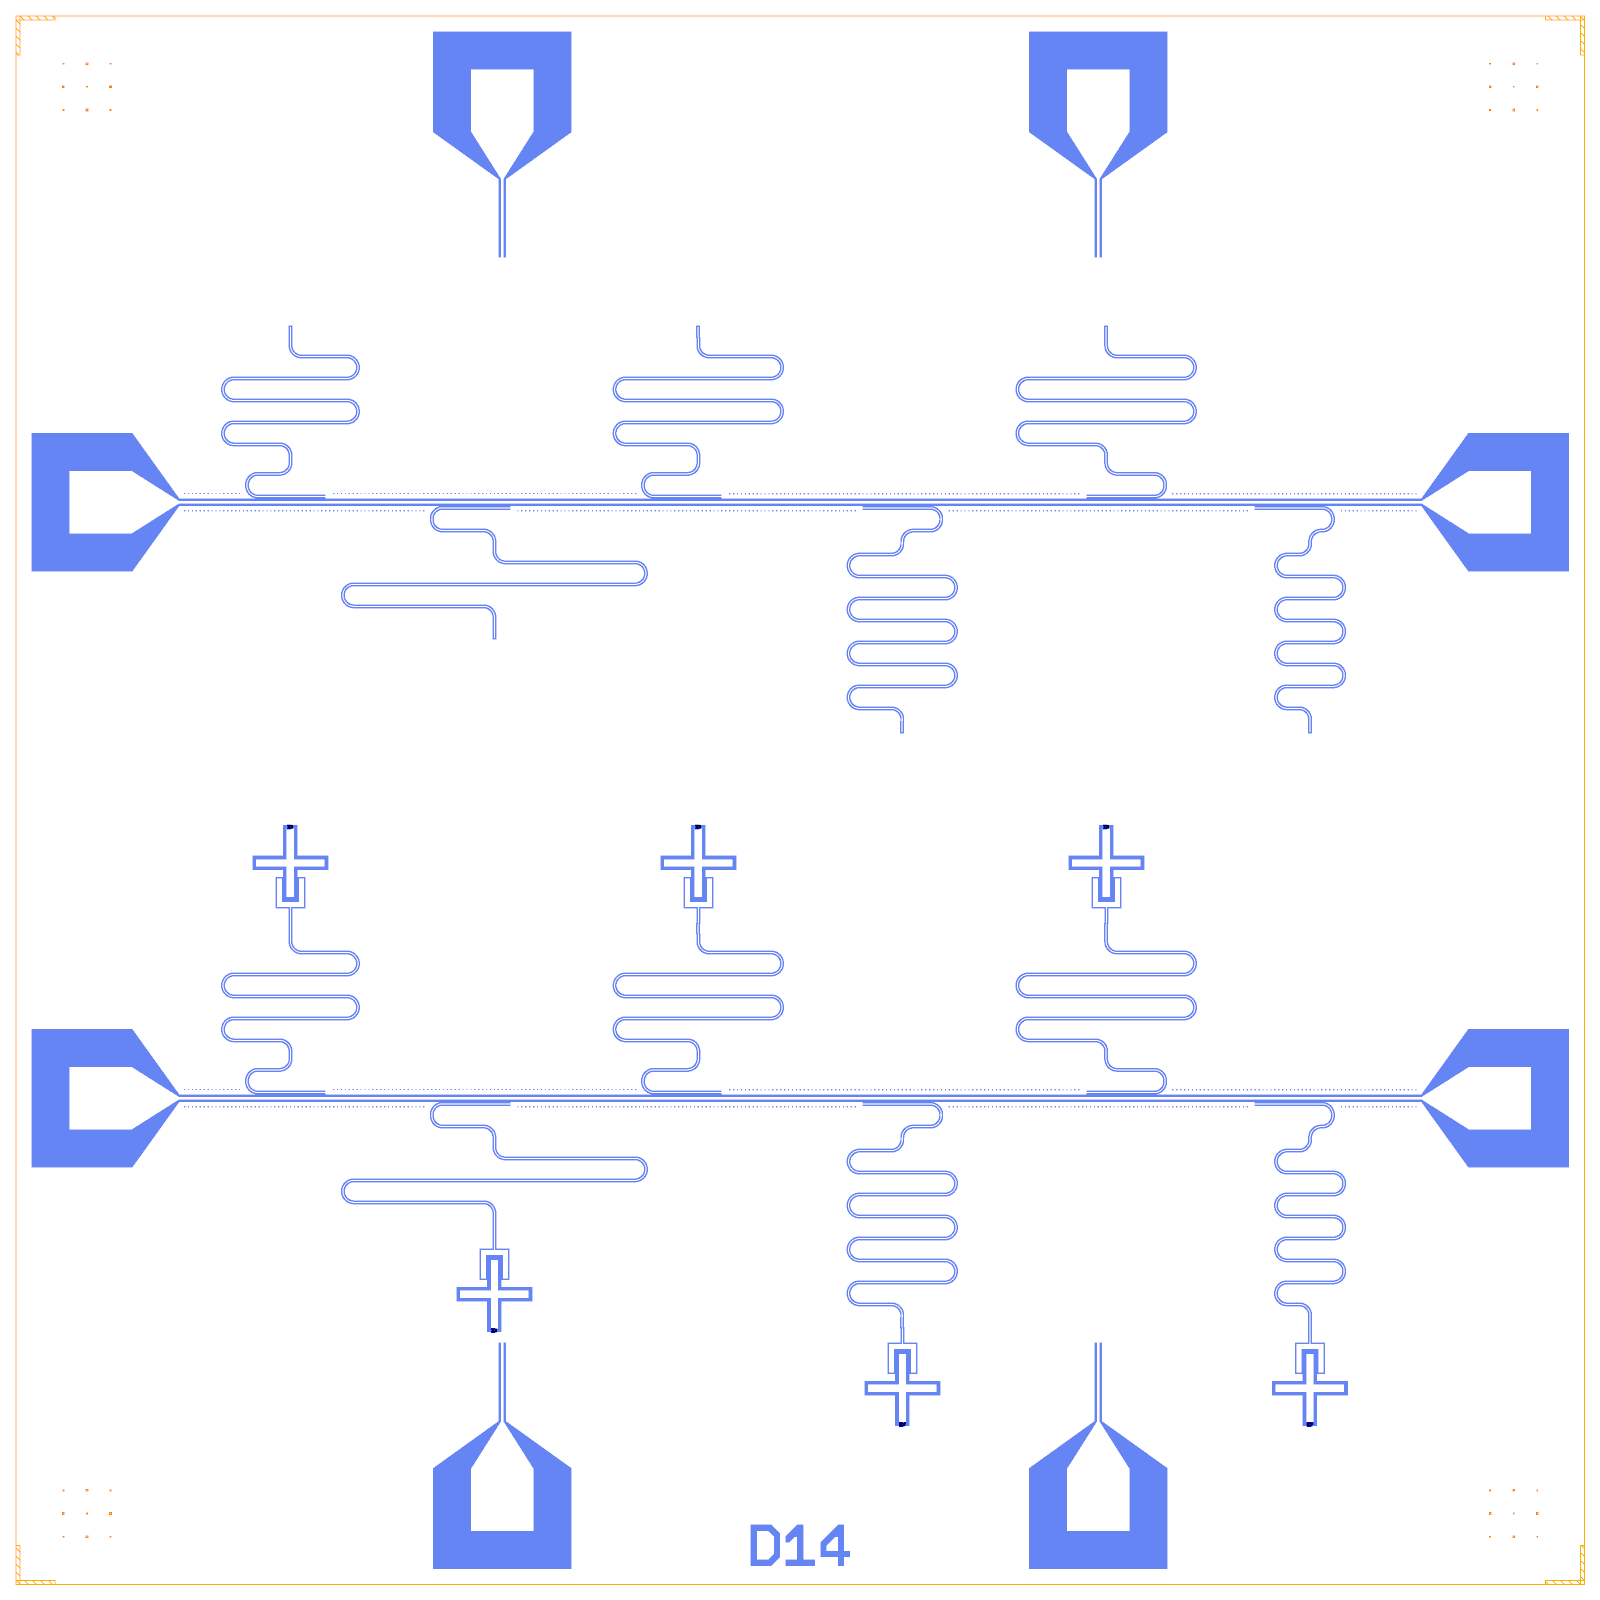

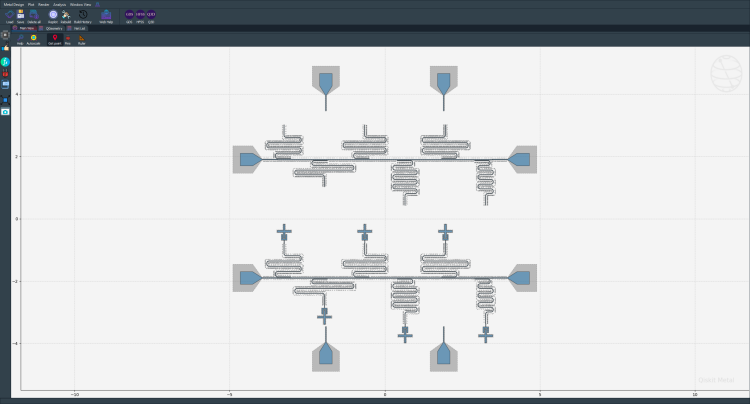

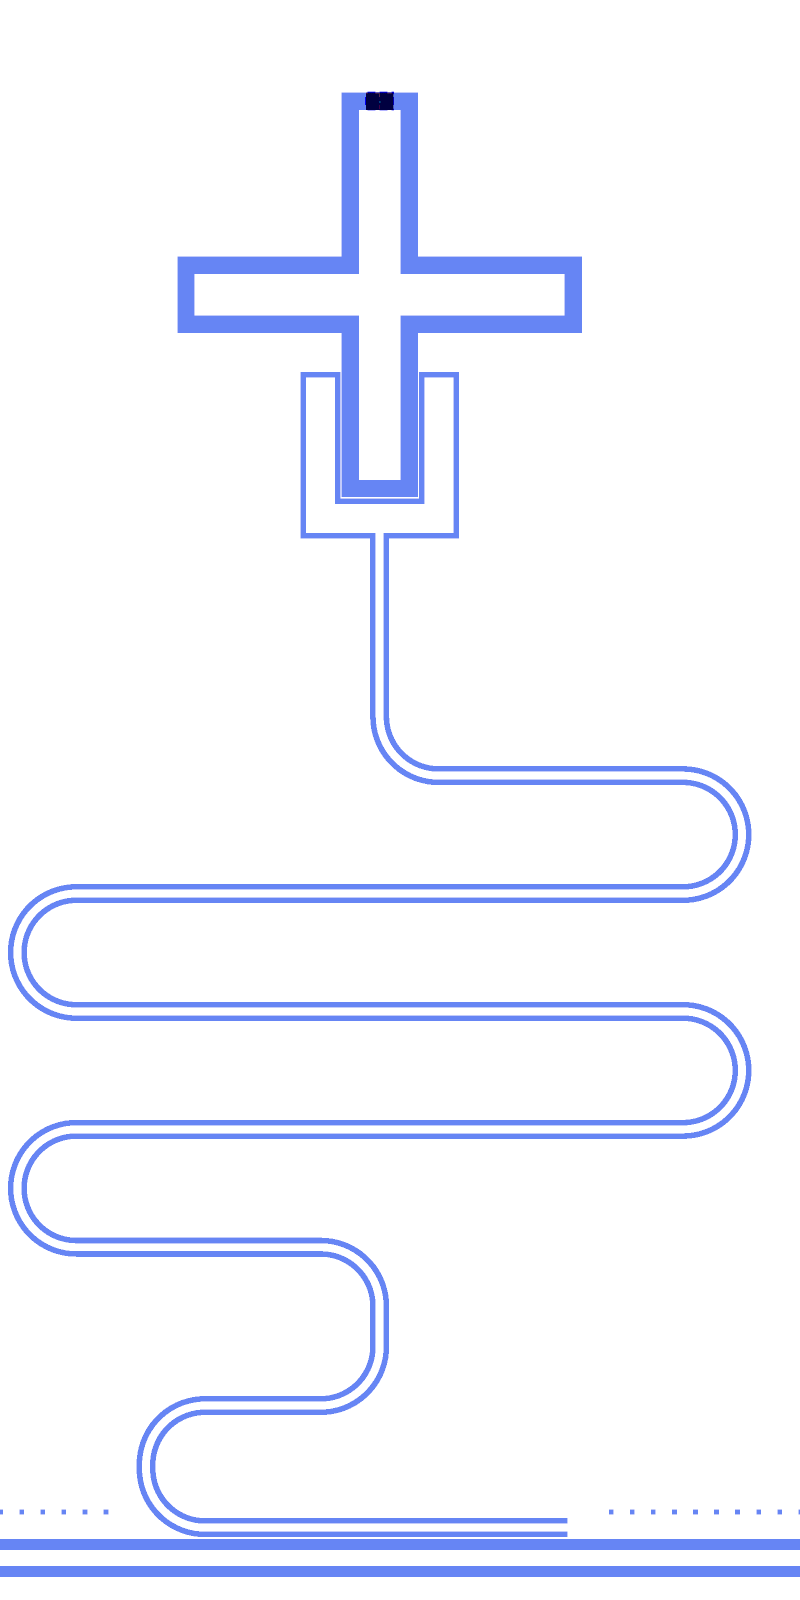

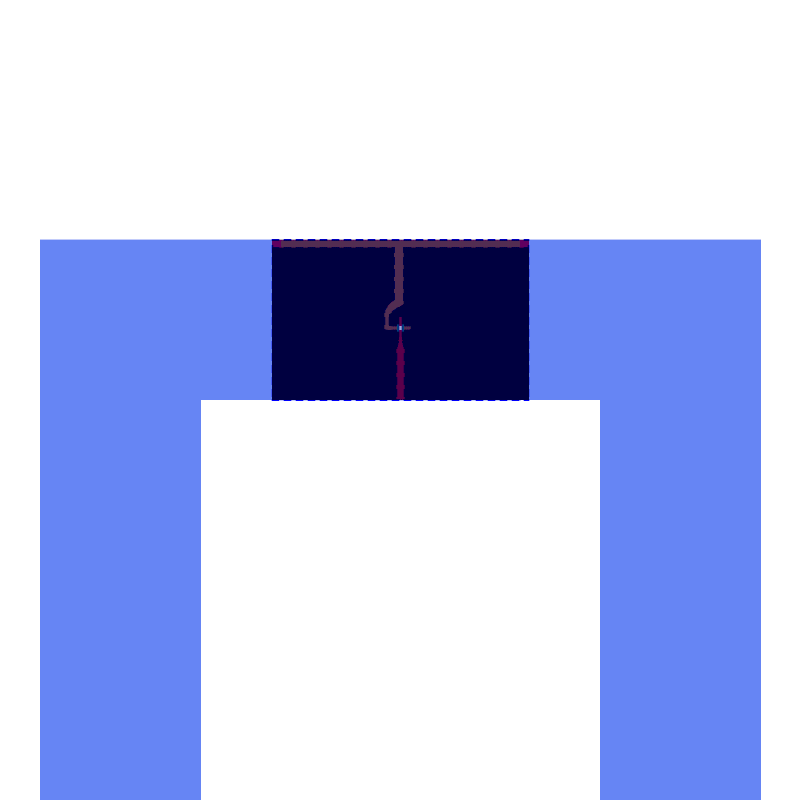

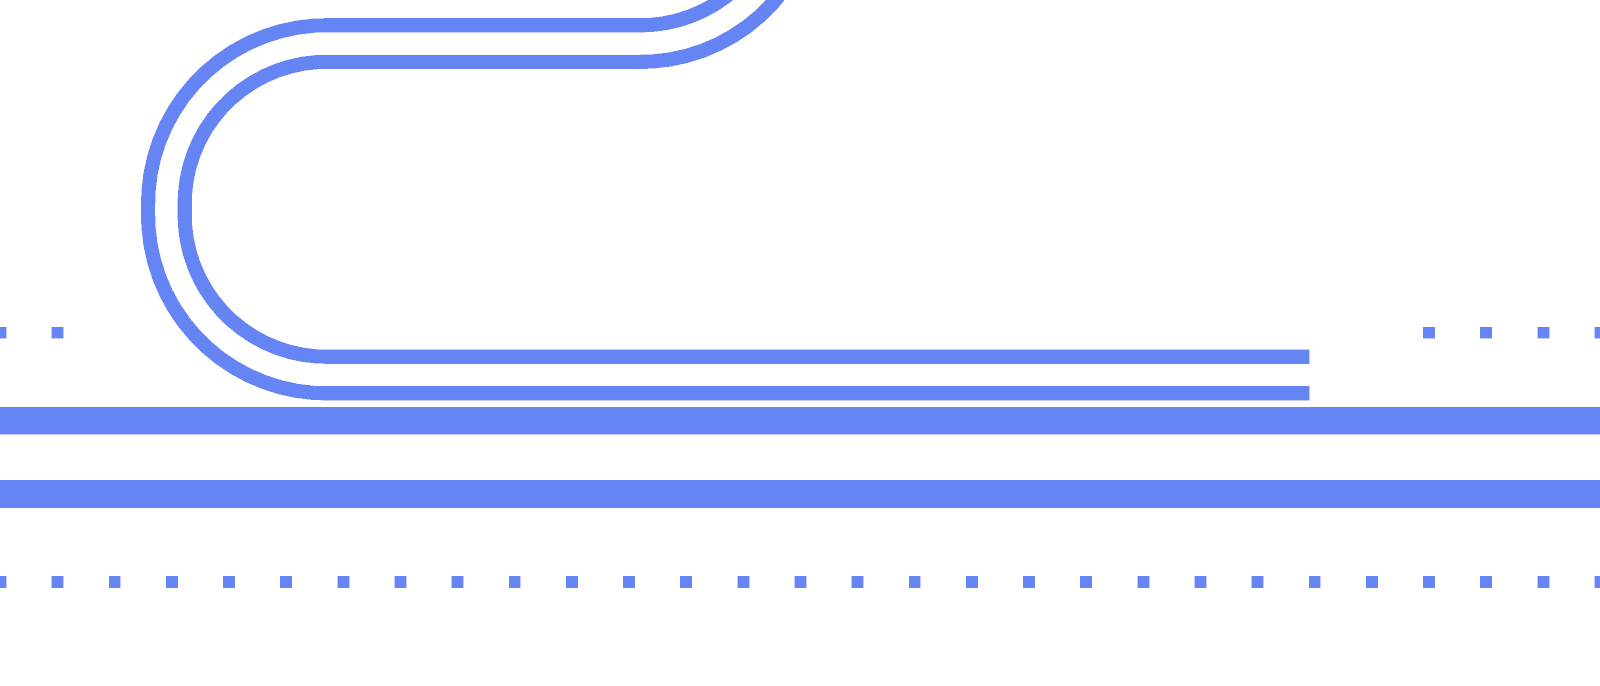

| route | legacy x (mm) | rebuilt x (mm) | legacy y (mm) | rebuilt y (mm) | max abs Δ (µm) |
|---|---|---|---|---|---|
| R_T0 | [-3.804, -2.696] | [-3.680, -2.820] | [1.936, 3.017] | [1.936, 3.006] | 124 |
| R_T1 | [-2.901, -0.999] | [-2.916, -0.984] | [1.033, 1.864] | [1.044, 1.864] | 15 |
| R_T2 | [-1.342, 0.042] | [-1.184, -0.116] | [1.936, 3.017] | [1.936, 3.006] | 158 |
| R_T3 | [0.260, 1.040] | [0.307, 0.993] | [0.433, 1.864] | [0.444, 1.864] | 47 |
| R_T4 | [1.215, 2.685] | [1.384, 2.516] | [1.936, 3.017] | [1.936, 3.006] | 169 |
| R_T5 | [2.896, 3.494] | [2.906, 3.467] | [0.433, 1.864] | [0.444, 1.864] | 27 |
| R_B0 | [-3.804, -2.696] | [-3.680, -2.820] | [-1.864, -0.783] | [-1.864, -0.794] | 124 |
| R_B1 | [-2.901, -0.999] | [-2.916, -0.984] | [-2.767, -1.936] | [-2.756, -1.936] | 15 |
| R_B2 | [-1.342, 0.042] | [-1.184, -0.116] | [-1.864, -0.783] | [-1.864, -0.794] | 158 |
| R_B3 | [0.260, 1.040] | [0.307, 0.993] | [-3.367, -1.936] | [-3.356, -1.936] | 47 |
| R_B4 | [1.215, 2.685] | [1.384, 2.516] | [-1.864, -0.783] | [-1.864, -0.794] | 169 |
| R_B5 | [2.896, 3.494] | [2.906, 3.467] | [-3.367, -1.936] | [-3.356, -1.936] | 27 |

In [17]:
C.show_snapshot(d, OUT / f"{ID}.png", size=(1600, 1600))
display(Image(filename=str(Path("docs/images/designs/legacy") / f"{ID}_legacy.png"), width=640))   # the legacy view
C.show_snapshot(d, OUT / f"{ID}_qubit.png", box=(1400, 3050, 2150, 4950), size=(800, 1600), width=320)   # Q_B0 + R_B0
C.show_snapshot(d, OUT / f"{ID}_junction.png", box=(1700, 4770, 1800, 4870), size=(800, 800), width=320)
C.show_snapshot(d, OUT / f"{ID}_coupler.png", box=(1400, 3000, 2100, 3300), size=(1600, 686), width=640)
built = LB.route_extents(d, LB.D14_LEGACY_EXTENTS, origin=(X0 + SHIFT[0], Y0 + SHIFT[1]), shrink=11)
display(Markdown(LB.extents_md(built, LB.D14_LEGACY_EXTENTS)))

## 16 · Summary

- **Matches the source:** the calibration and the §5 plan digit for digit; the 14 route lengths (feedlines 7880
  µm, resonators 4550 … 6405 µm); the couplers, shorts and open ends; resonator footprints within 15–47 µm of the
  legacy extents where the KQC meander keeps the arm layout, 124–169 µm where it picks fewer, wider arms (R_T0 / R_B0,
  R_T2 / R_B2, R_T4 / R_B4).
- **Cheese:** the PDK cheese over the whole die (`cheese: "chip"`, fab cheese source "build") plus the original's feedline flux holes (984 in 16 runs; an earlier pass had the PDK band around them, the next none).
- **Differs, by the PDK:** the PDK junction cells at 45 kΩ; the PDK frame and device ID `D14` on the 10 mm die
  (#10). The pads were already at `pad_edge` = 100 µm (nothing moved); centring shift (0, 0).
- **Open:** Q_B1/R_B1 hybridised (R_n 40 kΩ would move Q_B1 to 5.33 GHz, χ 111 → −24 MHz, step 13); the bottom row
  sits 0.6–1.1 GHz below its targets (#12); the meander rows of the §8 holes are not drawn (feedline rows only).